# Classification de l'espèce d'un iris : KNN vs Arbre de décision

**Durée estimée : 1h**

## Mise en situation
Vous êtes data scientist chez **FloraLab**, un laboratoire de botanique. La direction veut un outil qui reconnaît **automatiquement l'espèce d'un iris** (Setosa, Versicolor, Virginica) à partir de quatre mesures, sans expert.


## Comment utiliser ce notebook
- Chaque section contient une **explication** (cellule texte) suivie d'une **cellule de code à compléter**.
- Les lignes `# TODO` indiquent ce qu'il faut écrire, avec un **indice** sur la fonction à utiliser.
- Les cellules **Interprétation** sont à remplir avec vos propres mots : c'est ce qui est évalué en plus du code.
- Exécutez les cellules **dans l'ordre**.

## 0. Imports et configuration
*Cette cellule est déjà remplie. Ajoutez des imports si nécessaire.*

In [25]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, ConfusionMatrixDisplay, classification_report)

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")

## 1. Exploration et analyse des données (EDA)

### 1.1 Chargement et structure
**But :** comprendre la forme.
**À faire :** llire le dataset, puis afficher `head()`, `shape`, `info()` et `describe()`.



In [26]:
df = sns.load_dataset("iris")


In [27]:
df = sns.load_dataset("iris")
# TODO 1 : afficher head(), shape, info() et describe()
print("HEAD:\n",df.head())
print("Shape:",df.shape)
print("Info:",df.info())
print("Description:\n",df.describe())



HEAD:
    sepal_length  sepal_width  petal_length  petal_width species
0           5.1          3.5           1.4          0.2  setosa
1           4.9          3.0           1.4          0.2  setosa
2           4.7          3.2           1.3          0.2  setosa
3           4.6          3.1           1.5          0.2  setosa
4           5.0          3.6           1.4          0.2  setosa
Shape: (150, 5)
<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   sepal_length  150 non-null    float64
 1   sepal_width   150 non-null    float64
 2   petal_length  150 non-null    float64
 3   petal_width   150 non-null    float64
 4   species       150 non-null    str    
dtypes: float64(4), str(1)
memory usage: 7.2 KB
Info: None
Description:
        sepal_length  sepal_width  petal_length  petal_width
count    150.000000   150.000000    150.000000   150.000000
mean  

### 1.2 Types de variables, valeurs manquantes et doublons
**But :** repérer les problèmes de qualité.
**À faire :** identifier variables numériques et catégorielles, compter les valeurs manquantes et les doublons, vérifier qu'aucune mesure n'est négative ou nulle.


In [28]:
# TODO : types, valeurs manquantes, doublons, valeurs impossibles
print(df.duplicated().sum())
print(df.isna().sum())

1
sepal_length    0
sepal_width     0
petal_length    0
petal_width     0
species         0
dtype: int64


### 1.3 Équilibre des classes
**But :** savoir si l'accuracy sera une métrique fiable.
**À faire :** compter le nombre de fleurs par espèce et l'afficher dans un graphique en barres.


In [29]:
df["species"].unique()

<ArrowStringArray>
['setosa', 'versicolor', 'virginica']
Length: 3, dtype: str

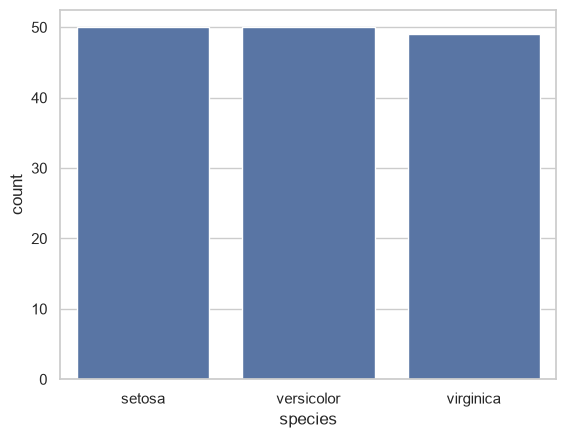

In [36]:
# TODO : value_counts + countplot ou graphique en barres
df.drop_duplicates(inplace=True)
df["species"].value_counts()
sns.countplot(x="species",data=df)
plt.show()

### 1.4 Distributions des variables
**But :** comprendre la forme de chaque mesure.
**À faire :** tracer un histogramme et un boxplot pour une variable(s) numérique(s), puis un boxplot **par espèce**.


<Axes: xlabel='sepal_length', ylabel='Count'>

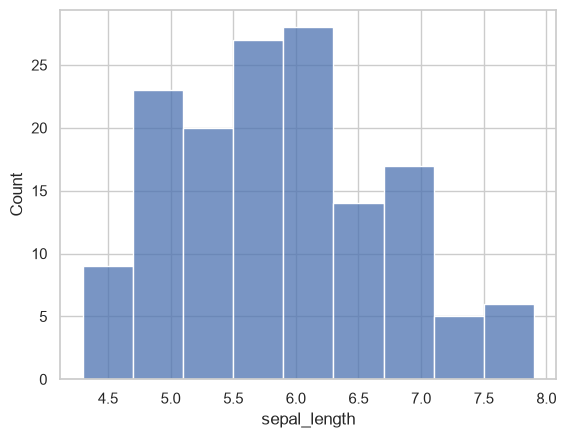

In [ ]:
# TODO : histogrammes
sns.histplot(data=df, x="sepal_length")



<Axes: xlabel='sepal_length'>

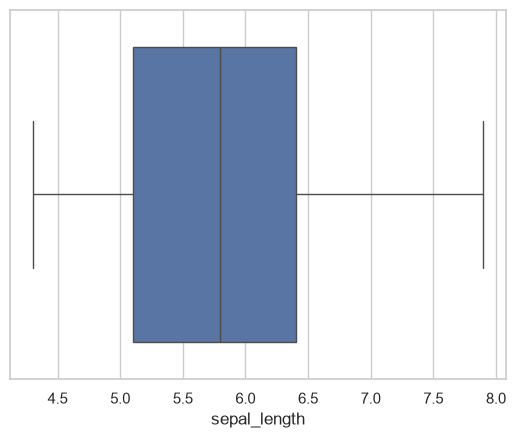

In [41]:
# TODO : boxplots par espèce
sns.boxplot(data=df , x="sepal_length")

### 1.5 Corrélations
**But :** repérer les variables redondantes.
**À faire :** calculer la matrice de corrélation des 4 mesures et l'afficher en heatmap.


In [42]:
# TODO : matrice de corrélation + heatmap

corr = df.select_dtypes('number').corr()
print(corr)

              sepal_length  sepal_width  petal_length  petal_width
sepal_length      1.000000    -0.118129      0.873738     0.820620
sepal_width      -0.118129     1.000000     -0.426028    -0.362894
petal_length      0.873738    -0.426028      1.000000     0.962772
petal_width       0.820620    -0.362894      0.962772     1.000000


<Axes: >

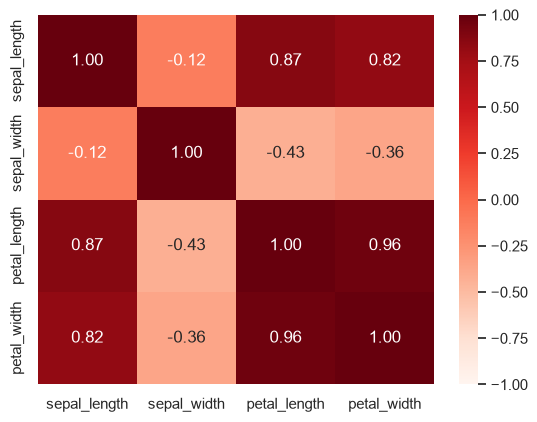

In [59]:

sns.heatmap(corr, 
            annot=True,       
            fmt=".2f",        
            cmap="Reds",  
            vmin=-1, vmax=1)

## 2. Nettoyage des données
**But :** obtenir un jeu de données fiable.
**À faire :**
1. Traiter les valeurs manquantes (s'il y en a).
2. Supprimer les doublons **seulement si c'est justifié**.
3. Corriger les valeurs impossibles.
4. Vérifier la qualité après nettoyage (shape, doublons, valeurs manquantes).


In [ ]:
# TODO : nettoyage (doublons, valeurs manquantes, incohérences)
# TODO : vérification après nettoyage
print("duplicates: ",df.duplicated().sum())

df=df.dropna()
print(" valeurs manquantes \n", df.isna().sum())



duplicates:  0
 valeurs manquantes 
 sepal_length    0
sepal_width     0
petal_length    0
petal_width     0
species         0
dtype: int64
2.0


**Justification de vos décisions de nettoyage :**

...

## 3. Préparation des données
**But :** séparer ce qu'on veut prédire de ce qui sert à prédire.
**À faire :**
- Définir `y` (la cible : l'espèce).
- Définir `X` (les 4 mesures).
- Lister les variables numériques, nominales et ordinales.
- Écarter les identifiants ou variables non pertinentes.

In [60]:
df.head()

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


In [63]:
# TODO : définir y
# TODO : définir X
# TODO : créer la liste num_features (variables numériques)

X = df.drop(columns="species")
y = df["species"]

num_features ={
    "sepal_length", 
    "sepal_width",
    "petal_length",
    "petal_width"
}
y.unique()

<ArrowStringArray>
['setosa', 'versicolor', 'virginica']
Length: 3, dtype: str

## 4. Séparation Train / Test
**But :** garder un jeu de test totalement indépendant pour l'évaluation finale.
**À faire :** séparer en 80 % / 20 % avec `random_state` et `stratify=y`, puis vérifier la répartition des espèces dans chaque ensemble.

> Le split se fait **avant** tout apprentissage de transformation (sinon : fuite de données).

In [73]:
# TODO : X_train, X_test, y_train, y_test = train_test_split(...)
# TODO : afficher la répartition des espèces dans y_train et y_test

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size= 0.2,
    random_state= 42,
    stratify= y
)

knn = KNeighborsClassifier(n_neighbors=5)

model = knn.fit(X_train,y_train)

knn_pred= knn.predict(X_test)



## 5. Prétraitement
**But :** préparer les transformations (sans encore les apprendre).
**À faire :**
- Créer un `ColumnTransformer` qui applique sur les variables numériques : `SimpleImputer(strategy='median')` puis `StandardScaler()`.
- Justifier l'absence d'`OneHotEncoder` et d'`OrdinalEncoder`.

In [ ]:
# TODO : numeric_transformer = Pipeline([...])
# TODO : preprocessor = ColumnTransformer([...])



numeric_transformer = Pipeline(steps=[
    ("imputer",SimpleImputer(strategy="median")),
    ("scaler", StandardScaler ),
])

preprocessor = ColumnTransformer(
    transformers=[   
    ("num",numeric_transformer,num_features)
],
remainder= "passthrough"
)






## 6. Construction des pipelines
**But :** enchaîner prétraitement + modèle dans un seul objet, pour éviter toute fuite de données pendant la validation croisée.
**À faire :** créer ** le pipeline ** :
- `pipe_knn` : preprocessor + `KNeighborsClassifier()`

> Dans un `Pipeline`, donnez des noms aux étapes (par ex. `'prep'` et `'model'`) : vous en aurez besoin pour la grille d'hyperparamètres (`model__n_neighbors`).

In [75]:
# TODO : pipe_knn = Pipeline([...])

pipe_knn= Pipeline(steps=[
    ("preprocessor" , preprocessor),
    ("model", KNeighborsClassifier(n_neighbors=5))
      
])

## 7. Entraînement
**But :** obtenir une première version du modèle avec les hyperparamètres par défaut.

- **Algorithme 1 : KNN** — classe une fleur selon ses voisins les plus proches (modèle de référence).

**À faire :** entraîner le pipeline sur `X_train`, `y_train` et afficher l'accuracy sur le train.

In [ ]:
# TODO : fit de pipe_knn
# TODO : afficher le score train de chacun (.score)

## 8. Validation croisée
**But :** estimer la performance de façon fiable.
**À faire :**
- Créer `cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)`.
- Calculer les scores de chaque pipeline avec `cross_val_score` (métrique `accuracy`, puis `f1_macro`).
- Afficher la **moyenne** des scores.


In [ ]:
# TODO : cv = StratifiedKFold(...)
# TODO : scores accuracy et f1_macro pour pipe_knn
# TODO : afficher moyenne

## 9. Optimisation des hyperparamètres (GridSearchCV)
**But :** trouver les meilleurs réglages.
**À faire :** définir une grille pour ton pipeline, lancer `GridSearchCV(..., cv=cv, scoring='f1_macro')` et afficher `best_params_` et `best_score_`.

Grilles suggérées :
- **KNN** : `model__n_neighbors` (2 à 5), `model__weights` (`uniform`, `distance`), `model__p` (1, 2).
> Le préfixe `model__` correspond au nom de l'étape dans votre pipeline.
> Le GridSearch ne doit utiliser que `X_train` et `y_train`.

In [ ]:
# TODO : param_grid_knn
# TODO : grid_knn = GridSearchCV(...) puis fit sur le train
# TODO : afficher best_params_ et best_score_

## 10. Évaluation sur le jeu de test
**But :** mesurer la performance réelle sur des données jamais vues.
**À faire :** pour chaque meilleur modèle (`best_estimator_`) :
1. Prédire sur `X_test`.
2. Calculer accuracy, précision (macro), rappel (macro) et F1 (macro).
3. Afficher la **matrice de confusion** et le `classification_report`.
4. Donner les valeurs ( TP , FP , TN , FN) pour chaque classe .

Rappel des métriques :
- **Accuracy** : proportion de fleurs bien classées.
- **Précision** : parmi les fleurs prédites d'une espèce, combien le sont vraiment.
- **Rappel** : parmi les fleurs réellement d'une espèce, combien sont retrouvées.
- **F1 macro** : moyenne du F1 des trois espèces, à égalité.

> Le jeu de test ne doit servir qu'ici, une seule fois.

In [ ]:
# TODO : best_knn = grid_knn.best_estimator_
# TODO : prédictions sur X_test
# TODO : métriques (accuracy, precision, recall, f1 avec average='macro')
# TODO : matrices de confusion (ConfusionMatrixDisplay.from_estimator)
# TODO : classification_report